# Kerbside parking through a day

The City of Melbourne's in-ground parking sensors recorded 42.7 million arrivals and departures in 2019. The events
name a street and its cross streets but carry no outline. In Python each sensor's state was read at half past every
hour of 2019 and summarised by street segment; in [Plotlay](https://www.getplotlay.com) the council's road corridor
outlines that held a sensor were taken from its file and keyed by `seg_id`, and the summaries linked to them.

This notebook reads only `../data` and recomputes the numbers on the page.

In [1]:
import pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
k = pd.read_csv(f'{DATA}/kerb/kerb_segments.csv')
h = pd.read_csv(f'{DATA}/kerb/kerb_hours.csv')
print(len(k), 'streets,', int(k.bays.sum()), 'bays')

257 streets, 5492 bays


## Sources and licence

On-street Car Parking Sensor Data 2019 and road corridors: City of Melbourne Open Data, CC BY 4.0. Only summaries per
street are here, never the event records. Full credits in `NOTICE`.

## How full, and how long

In [2]:
w = k.bays
print('occupied 8 am to 8 pm, weekdays:', round((k.occ_wd_8_20 * w).sum() / w.sum(), 1), '%; weekends:', round((k.occ_we_8_20 * w).sum() / w.sum(), 1), '%')
print('average stay:', round((k.avg_stay_min * k.stays).sum() / k.stays.sum(), 1), 'minutes; cars a bay a day:', round(k.stays.sum() / k.covered_bay_days.sum(), 1))
print('stays over the limit:', round((k.overstay_pct * k.stays).sum() / k.stays.sum(), 1), '%')

occupied 8 am to 8 pm, weekdays: 56.3 %; weekends: 59.2 %
average stay: 58.8 minutes; cars a bay a day: 10.8
stays over the limit: 9.4 %


## The kerb through a day (the average of the streets)

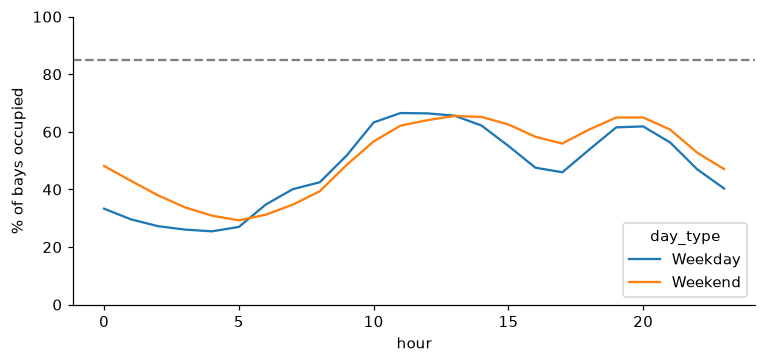

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Weekday,33.3,29.6,27.3,26.1,25.5,27.0,34.8,40.1,42.5,51.8,...,62.2,55.1,47.6,46.0,53.9,61.6,61.9,56.3,47.0,40.3
Weekend,48.1,43.0,38.0,33.8,30.9,29.3,31.2,34.7,39.4,48.5,...,65.2,62.6,58.3,55.9,60.8,65.0,65.0,60.8,52.8,47.1


In [3]:
day = h.groupby(['hour', 'day_type']).occupied.mean().unstack()
ax = day.plot(figsize=(8, 3.4)); ax.axhline(85, ls='--', c='grey'); ax.set_ylabel('% of bays occupied'); ax.set_ylim(0, 100)
plt.show()
day.round(1).T

## The streets (10 bays or more)

In [4]:
big = k[k.bays >= 10]
cols = ['name', 'bays', 'sign', 'occ_wd_8_20', 'avg_stay_min', 'stays_per_bay_day']
print('fullest'); display(big.sort_values('occ_wd_8_20', ascending=False)[cols].head(5))
print('longest stays'); display(big.sort_values('avg_stay_min', ascending=False)[cols].head(5))
print('most cars a bay a day'); display(big.sort_values('stays_per_bay_day', ascending=False)[cols].head(5))

fullest


,name,bays,sign,occ_wd_8_20,avg_stay_min,stays_per_bay_day
175,"Clarendon St, Albert St to Grey St",12,2P MTR M-F 7:30-18:30,87.1,101.0,9.29
71,"Queen St, Little Collins St to Collins St",13,1P MTR M-SAT 7:30-18:30,80.7,60.4,15.36
157,"Mackenzie St, Russell St to Victoria St",13,4P TKT A M-SAT 7:30-20:30,80.5,96.8,10.75
73,"Queen St, Little Bourke St to Bourke St",32,1P MTR M-SAT 7:30-18:30,80.3,49.6,16.69
50,"Exhibition St, Flinders Lane to Flinders St",32,2P MTR M-SAT 7:30-20:30,79.8,50.3,17.21


longest stays


,name,bays,sign,occ_wd_8_20,avg_stay_min,stays_per_bay_day
216,"Airlie St, Clowes St to The Righi",55,1P RPA 7:30am-10pm M-SUN,43.0,216.7,2.87
230,"Palmer St, Agnes St to Charles St",11,1P M-SUN 7:30-23:00,65.0,208.8,4.25
203,"Dodds St, Miles St to Coventry St",10,2P MTR M-F 7:30-18:30,73.4,195.5,4.62
215,"Walsh St, Domain Rd to Acland St",19,2P RPA 7:30AM-11PM M-SUN,56.4,184.4,4.58
153,"Simpson St, Albert St to Victoria Pde",23,1P M-SUN 7:30AM-10PM,67.8,184.0,4.82


most cars a bay a day


,name,bays,sign,occ_wd_8_20,avg_stay_min,stays_per_bay_day
45,"Collins St, Queen St to Elizabeth St",22,1/2P MTR M-SAT 7.30 TO 18.30,58.6,13.0,44.92
69,"Queen St, Flinders St to Flinders Lane",13,1P MTR M-SAT 7:30-18:30,50.6,14.4,38.06
44,"Collins St, Russell St to Exhibition St",15,2P DIS 7.30AM TO 8.30PM,74.2,26.5,31.55
62,"Russell St, Little Bourke St to Bourke St",16,LZ 15M M-F 7:30-19:30,64.1,29.0,31.04
65,"Elizabeth St, Collins St to Flinders Lane",13,1/2P MTR M-SAT 7.30 TO 18.30,63.0,32.8,28.90


## Plotlay's layer

`kerb.geojson` is Plotlay's export of the Kerb layer, keyed by `seg_id`, with the formula columns `full_hours_wd`
(`count(occupied_wd >= 85)`: weekday hours at 85% or fuller), `full_hours_we` and `weekend_vs_weekday`. The first is
worked out again here from the hour table.

In [5]:
g = gpd.read_file(f'{DATA}/geometry/kerb.geojson')
again = h[(h.day_type == 'Weekday') & (h.occupied >= 85)].groupby('seg_id').size()
m = g.assign(seg=g.key.astype(int)).set_index('seg').full_hours_wd.astype(float)
diff = (m - again.reindex(m.index).fillna(0)).abs().max()
print(len(g), 'streets in the layer; largest difference in full weekday hours:', diff)

257 streets in the layer; largest difference in full weekday hours: 0.0


## Read it carefully

- 2019, before the pandemic; the sensors have since been replaced.
- How full is read at half past each hour; a bay closed to parking reads as empty.
- A stay is 2 minutes to 24 hours; residents with permits are exempt from limits in their streets.